# 19 — Preparación del modelo: la historia, el EDA, la limpieza y la conversión
Hasta el notebook 18 el proyecto es **descriptivo**: mide la congestión, no la predice. Desde aquí se agrega un **modelo
supervisado** siguiendo el orden pedido para el informe: **1. preprocesamiento** (este notebook) → **2. modelo** (20) →
**3. evaluación** (21) → **4. despliegue** (22 y 23).

**La pregunta práctica.** Una persona va a presentar (o ya tiene) un caso: un divorcio en El Alto, una demanda laboral en
Santa Cruz. **¿Cuánto va a tardar?** El Anuario no sigue causas una por una, pero sí dice, para cada tipo de proceso en
cada lugar, cuántas causas había, cuántas entraron y cuántas se resolvieron. Con eso se mide la fila:

$$\text{tiempo estimado} = \frac{\text{causas pendientes al cierre del año}}{\text{causas resueltas en el año}} \times 365 \text{ días}$$

Es la `duracion_estimada_dias` del notebook 10 (la «duración estimada» del CEJA): si hay 600 causas esperando y el juzgado
resuelve 1.200 al año, la fila se termina en medio año. Un caso nuevo se pone al final de esa fila.

- **Unidad:** un tipo de proceso no penal en un territorio y una materia («divorcio, familia, Sucre capital»). Las materias
  penales quedan fuera porque el Anuario no publica sus causas resueltas.
- **Objetivo:** el tiempo estimado de 2023, en días. Es un número: el problema es de **regresión**.
- **Variables:** lo que se sabe al presentar el caso (cuántas causas esperan, cuántas entran, juzgados, personal, materia,
  lugar) y **la historia** de la materia.

Antes de modelar, la sección 1.1 usa los **años pasados** que trae el Anuario (capítulo 9: 2007-2023) para responder dos
preguntas que el año 2023 solo no puede: ¿el tiempo estimado se parece a lo que **de verdad** tardó la fila en vaciarse?
y ¿cuánto cambia de un año al siguiente?

In [1]:
%run -i modulos/comun.ipynb
%run -i modulos/modelado.ipynb
from scipy import stats

procesos = cargar_procesos()
datos = cargar_conjunto()
y = datos[OBJETIVO]
print(len(procesos), "procesos con movimiento;",
      int((procesos["atendidas"] >= MIN_CAUSAS).sum()), f"con al menos {MIN_CAUSAS} causas atendidas;",
      len(datos), "con al menos una resuelta (el conjunto del modelo)")
print(len(ORIGINALES), "variables originales;", len(INGENIERIA), "de ingeniería;", len(HISTORICAS), "histórica;",
      len(COMPLETA), "en total")
print("tiempo estimado: mediana", round(datos[DIAS].median()), "días; cuartiles",
      [round(v) for v in datos[DIAS].quantile([0.25, 0.75])])

1240 procesos con movimiento; 818 con al menos 10 causas atendidas; 808 con al menos una resuelta (el conjunto del modelo)
19 variables originales; 8 de ingeniería; 1 histórica; 28 en total
tiempo estimado: mediana 221 días; cuartiles [100, 503]


## Controles del conjunto
- El objetivo coincide con la `duracion_estimada_dias` del notebook 10 (salvo el tope de 10 años).
- Por qué **al menos 10 causas atendidas**: en la mitad de los procesos hubo 28 causas o menos en todo el año, y en
  muchos, 2 o 3. Con una sola causa resuelta y dos pendientes, el «tiempo» sería 730 días; con una más resuelta, 243. Eso
  no mide una fila, mide la suerte de una causa. El filtro mira las causas **atendidas** (stock heredado + ingresos: un
  dato de entrada), no las resueltas ni el tiempo: no elige ejemplos mirando la respuesta.
- Los procesos con 10 o más causas y **ninguna** resuelta no tienen tiempo (dividir por cero): quedan fuera del
  entrenamiento y la página los muestra aparte.
- Ninguna columna excluida por fuga entra al modelo.

In [2]:
grandes = procesos[procesos["atendidas"] >= MIN_CAUSAS]
sin_resueltas = int((grandes["resueltas"] == 0).sum())
chicos = procesos[procesos["atendidas"] < MIN_CAUSAS]
print(len(chicos), f"procesos con menos de {MIN_CAUSAS} causas (fuera del entrenamiento; la página los marca);",
      "mediana de causas atendidas en todos:", int(procesos["atendidas"].median()))
print(sin_resueltas, "procesos con", MIN_CAUSAS, "o más causas y ninguna resuelta (sin tiempo)")
nb10 = grandes.loc[grandes["resueltas"] > 0, "duracion_estimada_dias"].astype(float).to_numpy()
assert np.allclose(np.minimum(nb10, TOPE_DIAS), datos[DIAS].to_numpy()), "el objetivo no coincide con el notebook 10"
assert not set(FUGA) & set(COMPLETA), "una variable con fuga se coló en el modelo"
assert set(FUGA) <= set(procesos.columns), "una columna de la lista de fuga no existe"
assert len(set(COMPLETA)) == len(COMPLETA)
topados = int((nb10 > TOPE_DIAS).sum())
print(topados, "procesos con más de 10 años de fila quedan en 3.650 días")
print("controles OK")

422 procesos con menos de 10 causas (fuera del entrenamiento; la página los marca); mediana de causas atendidas en todos: 28
10 procesos con 10 o más causas y ninguna resuelta (sin tiempo)
13 procesos con más de 10 años de fila quedan en 3.650 días
controles OK


## 1.1 Lo que enseña la historia (2007-2023)
El capítulo 9 del Anuario trae el movimiento de causas **no penales y penales juntas** de 17 años, para las capitales, las
provincias y el país (cuadros 9.1.4, 9.1.8 y 9.1.12; notebook 15). No baja al tipo de proceso, pero alcanza para poner a
prueba la medida que usará el modelo.

### a) El tiempo estimado, año por año

In [3]:
serie = pd.read_parquet(PROCESSED / "causas_serie_historica.parquet")
for c in ["pendientes_inicio", "ingresadas", "resueltas", "pendientes_fin"]:
    serie[c] = serie[c].astype(float)
serie["tiempo_dias"] = serie["pendientes_fin"] / serie["resueltas"] * 365
tiempos = serie.pivot_table(index="gestion", columns="ambito", values="tiempo_dias")[["nacional", "capital", "provincia"]]
display(tiempos.round(0).T)

gestion,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
ambito,,,,,,,,,,,,,,,,,
nacional,359.0,355.0,392.0,427.0,445.0,448.0,417.0,404.0,316.0,393.0,384.0,352.0,388.0,485.0,377.0,379.0,340.0
capital,395.0,387.0,425.0,448.0,467.0,467.0,427.0,421.0,327.0,418.0,387.0,353.0,395.0,511.0,378.0,373.0,331.0
provincia,247.0,257.0,290.0,351.0,361.0,380.0,381.0,350.0,282.0,322.0,374.0,350.0,370.0,422.0,374.0,394.0,365.0


### b) ¿La fila se vació en el tiempo estimado?
Al cierre de cada año quedan $P$ causas pendientes. El tiempo estimado dice que se terminarán en $P / R \times 365$ días.
Con los años siguientes se puede ver cuánto tardó **de verdad** el sistema en resolver esa cantidad de causas: se suman
las resueltas de los años siguientes hasta llegar a $P$ (dentro del último año, en proporción a los días). Es lo que tardó
en atenderse una causa que llegó al final de la fila. Es una comprobación aproximada: supone que las causas se resuelven
en orden de llegada y el Anuario no dice cuáles se resolvieron, solo cuántas.

In [4]:
filas_vaciado = []
for ambito, g in serie.groupby("ambito"):
    g = g.sort_values("gestion").set_index("gestion")
    for t in g.index:
        falta, anios = g.loc[t, "pendientes_fin"], 0.0
        for u in g.index[g.index > t]:
            r = g.loc[u, "resueltas"]
            if r >= falta:
                anios += falta / r
                falta = 0
                break
            falta -= r
            anios += 1
        real = anios * 365 if falta == 0 else np.nan
        filas_vaciado.append({"ambito": ambito, "gestion": t, "tiempo_estimado": g.loc[t, "tiempo_dias"],
                              "tiempo_real_vaciado": real})
vaciado = pd.DataFrame(filas_vaciado).dropna()
vaciado["error_pct"] = (vaciado["tiempo_estimado"] / vaciado["tiempo_real_vaciado"] - 1) * 100
display(vaciado[vaciado["ambito"] == "nacional"].round(0).set_index("gestion").T)
print(len(vaciado), "comprobaciones (3 ámbitos x años con suficientes años siguientes)")
print("error absoluto: mediana", round(vaciado["error_pct"].abs().median(), 1), "% · media",
      round(vaciado["error_pct"].abs().mean(), 1), "% · sesgo (mediana del error)", round(vaciado["error_pct"].median(), 1), "%")

gestion,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
ambito,nacional,nacional,nacional,nacional,nacional,nacional,nacional,nacional,nacional,nacional,nacional,nacional,nacional,nacional,nacional,nacional
tiempo_estimado,359.0,355.0,392.0,427.0,445.0,448.0,417.0,404.0,316.0,393.0,384.0,352.0,388.0,485.0,377.0,379.0
tiempo_real_vaciado,313.0,338.0,384.0,414.0,380.0,388.0,398.0,328.0,357.0,466.0,394.0,363.0,470.0,380.0,358.0,348.0
error_pct,15.0,5.0,2.0,3.0,17.0,15.0,5.0,23.0,-11.0,-16.0,-2.0,-3.0,-18.0,28.0,5.0,9.0


47 comprobaciones (3 ámbitos x años con suficientes años siguientes)
error absoluto: mediana 11.7 % · media 12.4 % · sesgo (mediana del error) 5.4 %


### c) ¿Cuánto cambia el tiempo de un año al siguiente?
Si el tiempo de este año se parece al del próximo, el dato del último Anuario sirve para quien presenta su caso después.
Se comparan tres formas de anticipar el tiempo del año $t$ con lo que se sabía antes:

| forma | cálculo | qué supone |
|---|---|---|
| **el del año anterior** | tiempo de $t-1$ | que la fila se mueve igual que el año pasado |
| **fórmula ingenua** | stock heredado de $t$ ÷ ingresos de $t$ × 365 | que se resuelve tanto como entra |
| **stock ÷ ritmo anterior** | stock heredado de $t$ ÷ resueltas de $t-1$ × 365 | que se resuelve como el año pasado |

In [5]:
filas_pers = []
for ambito, g in serie.groupby("ambito"):
    g = g.sort_values("gestion").set_index("gestion")
    for t in g.index[1:]:
        filas_pers.append({
            "ambito": ambito, "gestion": t, "real": g.loc[t, "tiempo_dias"],
            "el del año anterior": g.loc[t - 1, "tiempo_dias"],
            "fórmula ingenua": g.loc[t, "pendientes_inicio"] / g.loc[t, "ingresadas"] * 365,
            "stock ÷ ritmo anterior": g.loc[t, "pendientes_inicio"] / g.loc[t - 1, "resueltas"] * 365,
        })
pers = pd.DataFrame(filas_pers)
FORMAS = ["el del año anterior", "fórmula ingenua", "stock ÷ ritmo anterior"]
resumen_formas = pd.DataFrame({
    f: {"error_abs_mediano_pct": ((pers[f] / pers["real"] - 1).abs() * 100).median(),
        "error_abs_medio_pct": ((pers[f] / pers["real"] - 1).abs() * 100).mean(),
        "sesgo_pct": ((pers[f] / pers["real"] - 1) * 100).median(),
        "peor_pct": ((pers[f] / pers["real"] - 1).abs() * 100).max()} for f in FORMAS}).T
display(resumen_formas.round(1))
cambio = (pers["real"] / pers["el del año anterior"] - 1) * 100
print("años en que el tiempo cambió más de 20 %:",
      pers.loc[cambio.abs() > 20, ["ambito", "gestion"]].assign(cambio=cambio.round(0)).to_dict("records"))

,error_abs_mediano_pct,error_abs_medio_pct,sesgo_pct,peor_pct
el del año anterior,8.8,10.3,-0.4,35.2
fórmula ingenua,25.0,24.7,-24.1,51.1
stock ÷ ritmo anterior,18.2,15.3,-10.6,40.7


años en que el tiempo cambió más de 20 %: [{'ambito': 'capital', 'gestion': 2015, 'cambio': -22.0}, {'ambito': 'capital', 'gestion': 2016, 'cambio': 28.0}, {'ambito': 'capital', 'gestion': 2020, 'cambio': 29.0}, {'ambito': 'capital', 'gestion': 2021, 'cambio': -26.0}, {'ambito': 'nacional', 'gestion': 2015, 'cambio': -22.0}, {'ambito': 'nacional', 'gestion': 2016, 'cambio': 24.0}, {'ambito': 'nacional', 'gestion': 2020, 'cambio': 25.0}, {'ambito': 'nacional', 'gestion': 2021, 'cambio': -22.0}, {'ambito': 'provincia', 'gestion': 2010, 'cambio': 21.0}]


### d) Las materias: cómo cambió su ritmo de resolución (2020-2023)
Por materia el Anuario solo trae las **resueltas** de 2019 a 2023 (cuadros 9.1.2 y 9.1.6), separadas en capitales y
provincias. 2019 no se usa (el notebook 15 mostró que no cuadra con los totales) y 2020 es el año de la pandemia. De ahí
sale la **variable histórica** del modelo: cuánto cambiaron las resoluciones de la materia **el año anterior** al caso.
Para un caso de 2023 es $\text{resueltas}_{2022} / \text{resueltas}_{2021} - 1$; para uno de 2024 será
$\text{resueltas}_{2023} / \text{resueltas}_{2022} - 1$. Usa solo años pasados: no espía el año que se predice.

In [6]:
NO_PENALES = list(datos["materia_homologada"].unique())
rm = resueltas_por_materia()
rm = rm[rm.index.get_level_values("materia_homologada").isin(NO_PENALES)][[2020, 2021, 2022, 2023]]
hist_materias = rm.copy()
hist_materias["tendencia_para_2023"] = tendencia_historica(2023)
hist_materias["tendencia_para_2024"] = tendencia_historica(2024)
display(hist_materias.round(3))
assert datos["tendencia_resueltas_materia"].notna().all(), "una materia y ámbito sin historia"

gestion                                                        2020   2021  \
ambito    materia_homologada                                                 
capital   Partido Administrativo Coactivo Fiscal y Tribut...   2114   2110   
          Partido de Trabajo y Seguridad Social               13497  15362   
          Público Civil y Comercial                           38356  52219   
          Público Niñez y Adolescencia                         5176   6964   
          Público de Familia                                  34802  53128   
provincia Partido de Trabajo y Seguridad Social                1219   1469   
          Público Civil y Comercial                           15736  21641   
          Público Niñez y Adolescencia                         2002   1978   
          Público de Familia                                  18417  22444   

gestion                                                        2022   2023  \
ambito    materia_homologada                                                 
capital   Partido Administrativo Coactivo Fiscal y Tribut...   2518   2671   
          Partido de Trabajo y Seguridad Social               15929  20797   
          Público Civil y Comercial                           58647  67788   
          Público Niñez y Adolescencia                         6760   8368   
          Público de Familia                                  52685  52523   
provincia Partido de Trabajo y Seguridad Social                2066   2644   
          Público Civil y Comercial                           26574  26981   
          Público Niñez y Adolescencia                         2350   3344   
          Público de Familia                                  26476  26687   

gestion                                                       tendencia_para_2023  \
ambito    materia_homologada                                                        
capital   Partido Administrativo Coactivo Fiscal y Tribut...                0.193   
          Partido de Trabajo y Seguridad Social                             0.037   
          Público Civil y Comercial                                         0.123   
          Público Niñez y Adolescencia                                     -0.029   
          Público de Familia                                               -0.008   
provincia Partido de Trabajo y Seguridad Social                             0.406   
          Público Civil y Comercial                                         0.228   
          Público Niñez y Adolescencia                                      0.188   
          Público de Familia                                                 0.18   

gestion                                                       tendencia_para_2024  
ambito    materia_homologada                                                       
capital   Partido Administrativo Coactivo Fiscal y Tribut...                0.061  
          Partido de Trabajo y Seguridad Social                             0.306  
          Público Civil y Comercial                                         0.156  
          Público Niñez y Adolescencia                                      0.238  
          Público de Familia                                               -0.003  
provincia Partido de Trabajo y Seguridad Social                              0.28  
          Público Civil y Comercial                                         0.015  
          Público Niñez y Adolescencia                                      0.423  
          Público de Familia                                                0.008

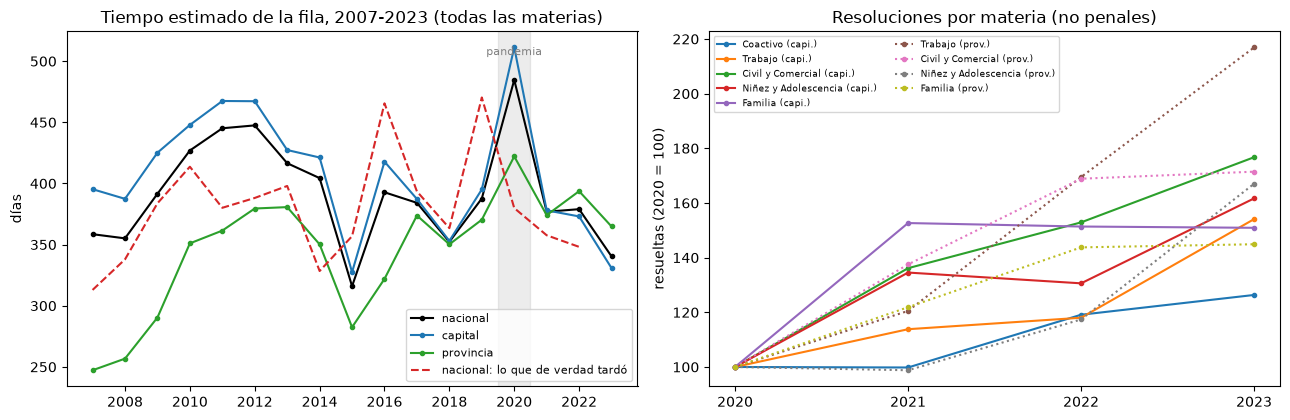

In [7]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = ejes[0]
for ambito, color in [("nacional", "black"), ("capital", "tab:blue"), ("provincia", "tab:green")]:
    ax.plot(tiempos.index, tiempos[ambito], marker="o", ms=3, color=color, label=ambito)
nac = vaciado[vaciado["ambito"] == "nacional"]
ax.plot(nac["gestion"], nac["tiempo_real_vaciado"], ls="--", color="tab:red", label="nacional: lo que de verdad tardó")
ax.axvspan(2019.5, 2020.5, color="gray", alpha=0.15)
ax.text(2020, 505, "pandemia", ha="center", fontsize=8, color="gray")
ax.set_ylabel("días")
ax.set_title("Tiempo estimado de la fila, 2007-2023 (todas las materias)")
ax.legend(fontsize=8)
ax = ejes[1]
norm = rm.div(rm[2020], axis=0) * 100
for (ambito, materia), fila in norm.iterrows():
    corta = materia.replace("Público ", "").replace("Partido ", "").replace("Administrativo ", "").replace("de ", "").replace(" y Seguridad Social", "").replace(" Fiscal y Tributario", "")
    ax.plot(fila.index, fila.values, marker="o", ms=3, ls="-" if ambito == "capital" else ":",
            label=f"{corta} ({ambito[:4]}.)")
ax.set_xticks([2020, 2021, 2022, 2023])
ax.set_ylabel("resueltas (2020 = 100)")
ax.set_title("Resoluciones por materia (no penales)")
ax.legend(fontsize=6.5, ncol=2)
plt.tight_layout()
guardar_figura(fig, "nb19_1.png")
plt.show()

In [8]:
tiempos.reset_index().to_csv(MODELO_DIR / "historia_tiempos.csv", index=False)
vaciado.to_csv(MODELO_DIR / "historia_vaciado.csv", index=False)
pers.to_csv(MODELO_DIR / "historia_anio_siguiente.csv", index=False)
resumen_formas.to_csv(MODELO_DIR / "historia_formas.csv")
hist_materias.reset_index().rename(columns=str).to_csv(MODELO_DIR / "historia_materias.csv", index=False)
print("guardado: historia_tiempos, historia_vaciado, historia_anio_siguiente, historia_formas, historia_materias")

guardado: historia_tiempos, historia_vaciado, historia_anio_siguiente, historia_formas, historia_materias


## 1.2 EDA: cómo se ve el objetivo
Primero, cuánto cambia el tiempo según la materia y el ámbito. Si fuera igual en todas partes, esas variables no
servirían para predecir. Se resume con la **mediana**, porque unos pocos procesos lentísimos tirarían el promedio.

In [9]:
resumen_materia = (datos.groupby("materia_homologada")[DIAS]
                   .agg(procesos="size", mediana="median", p25=lambda s: s.quantile(0.25), p75=lambda s: s.quantile(0.75))
                   .sort_values("mediana", ascending=False))
resumen_ambito = datos.groupby("ambito")[DIAS].agg(procesos="size", mediana="median")
display(resumen_materia.round(0))
display(resumen_ambito.round(0))

,procesos,mediana,p25,p75
materia_homologada,,,,
Partido Administrativo Coactivo Fiscal y Tributario,24,887.0,237.0,2117.0
Partido de Trabajo y Seguridad Social,109,375.0,159.0,964.0
Público Civil y Comercial,268,243.0,111.0,487.0
Público de Familia,238,195.0,116.0,326.0
Público Niñez y Adolescencia,169,146.0,52.0,469.0


,procesos,mediana
ambito,,
capital,496,209.0
provincia,312,236.0


Ahora cada variable numérica frente al objetivo. Se usa la **correlación de Spearman** (por rangos), porque las
cantidades de causas son muy asimétricas y un proceso enorme no debe dominar la medida.

In [10]:
numericas = [c for c in COMPLETA if c not in CATEGORICAS]
filas_corr = []
for c in numericas:
    rho, p = stats.spearmanr(datos[c], y, nan_policy="omit")
    grupo = "original" if c in ORIGINALES else ("histórica" if c in HISTORICAS else "ingeniería")
    filas_corr.append({"variable": c, "nombre": NOMBRES[c], "grupo": grupo,
                       "spearman": rho, "p_valor": p, "asimetria": stats.skew(datos[c].dropna())})
corr = pd.DataFrame(filas_corr).sort_values("spearman", key=abs, ascending=False)
corr.to_csv(MODELO_DIR / "eda_correlaciones.csv", index=False)
display(corr.round(3))

,variable,nombre,grupo,spearman,p_valor,asimetria
18,presion_stock,presión del stock,ingeniería,0.636,0.000,11.247
11,personal_items_mujer,puestos ocupados por mujeres,original,0.312,0.000,0.081
15,personal_remun_total,remuneración total,original,0.291,0.000,0.197
14,personal_items_total,puestos totales,original,0.291,0.000,0.218
9,recurso_tribunales_publicados,tribunales del territorio,original,0.280,0.000,0.106
12,personal_items_varon,puestos ocupados por varones,original,0.278,0.000,0.393
13,personal_items_acefalias,puestos vacantes,original,0.275,0.000,0.684
19,ingresos_por_juzgado,ingresos por juzgado,ingeniería,-0.260,0.000,3.522
0,pendientes_inicio_efectivo,stock heredado,original,0.234,0.000,5.537
16,log_stock_inicial,log del stock heredado,ingeniería,0.234,0.000,0.320


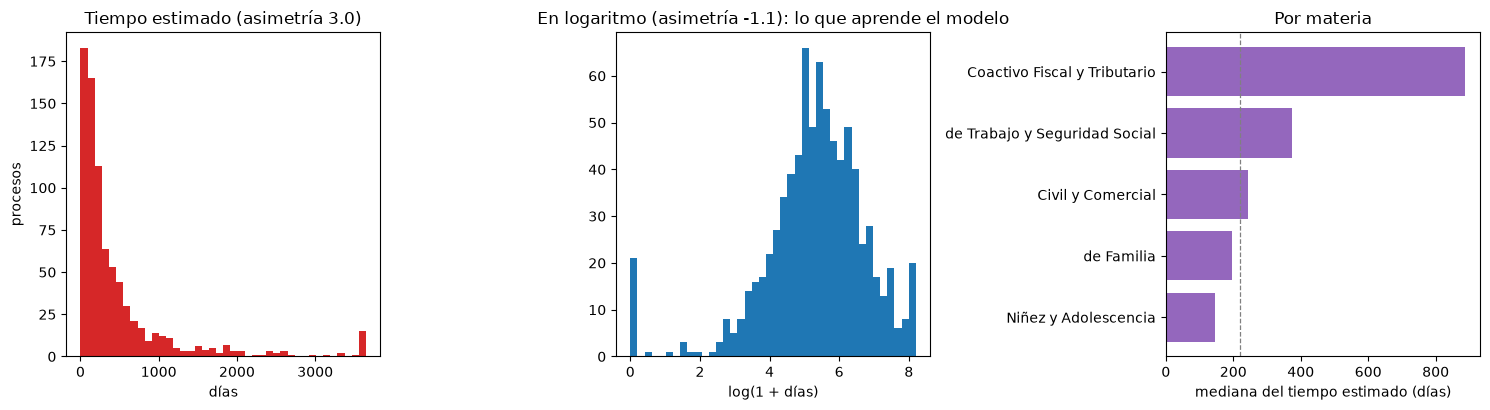

In [11]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.2))
ax = ejes[0]
ax.hist(datos[DIAS], bins=40, color="tab:red")
ax.set_xlabel("días")
ax.set_ylabel("procesos")
ax.set_title(f"Tiempo estimado (asimetría {stats.skew(datos[DIAS]):.1f})")
ax = ejes[1]
ax.hist(y, bins=40, color="tab:blue")
ax.set_xlabel("log(1 + días)")
ax.set_title(f"En logaritmo (asimetría {stats.skew(y):.1f}): lo que aprende el modelo")
ax = ejes[2]
etiquetas = [m.replace("Público ", "").replace("Partido ", "").replace("Administrativo ", "") for m in resumen_materia.index]
ax.barh(etiquetas[::-1], resumen_materia["mediana"][::-1], color="tab:purple")
ax.axvline(datos[DIAS].median(), color="gray", ls="--", lw=0.9)
ax.set_xlabel("mediana del tiempo estimado (días)")
ax.set_title("Por materia")
plt.tight_layout()
guardar_figura(fig, "nb19_2.png")
plt.show()

## 1.3 Limpieza
**Fuga de información.** Es el error más grave al preparar un modelo: usar como pista algo que contiene la respuesta.
El tiempo se calcula con las **resueltas** y los **pendientes al cierre**; cualquier columna hecha con ellas le «dice» al
modelo la respuesta. Se excluyen todas:

In [12]:
tabla_fuga = pd.DataFrame({"columna": list(FUGA), "motivo": list(FUGA.values())})
display(tabla_fuga)

,columna,motivo
0,resueltas,es parte de la respuesta: el tiempo se divide ...
1,pendientes_fin,es parte de la respuesta: el tiempo es pendien...
2,duracion_estimada_dias,es el objetivo
3,duracion_estimada_winsorizada,es el objetivo recortado
4,tasa_resolucion,resueltas / ingresos
5,tasa_resolucion_con_readecuadas,usa resueltas
6,tasa_resolucion_solo_nuevas,usa resueltas
7,tasa_congestion,atendidas / resueltas
8,tasa_pendencia,usa pendientes al cierre
9,acumulacion_neta_anual,ingresos - resueltas


**Valores faltantes.** Dos formas de ingreso (preliminares y cautelares formalizados) solo existen en civil: en las otras
materias el faltante no es un dato perdido, es un **cero estructural**, y se llenó con 0 al cargar. Lo que queda faltante
se imputa con la **mediana del entrenamiento** dentro del modelo (así la prueba no influye en el valor imputado).

In [13]:
faltantes = datos[COMPLETA].isna().sum()
faltantes = faltantes[faltantes > 0]
display(faltantes.rename("faltantes").to_frame())
assert faltantes.sum() < 0.01 * len(datos) * len(COMPLETA), "más faltantes de los esperados"
assert (datos["num_juzgados_pagina"] > 0).all(), "un proceso sin juzgados haría infinita la carga por juzgado"

,faltantes
recurso_tribunales_publicados,4


**Valores atípicos.** No se eliminan procesos: uno con muchas causas es real (lo verificó el notebook 11 contra el PDF).
Dos decisiones: el objetivo se **recorta en 10 años** (más que eso es «no se mueve», y un número como 80 años no es un
plazo) y se modela su **logaritmo**, que acerca los extremos sin borrarlos. Para los modelos sensibles a la escala (SVM y
regresión lineal) se agregan versiones en logaritmo y cocientes de las cantidades.

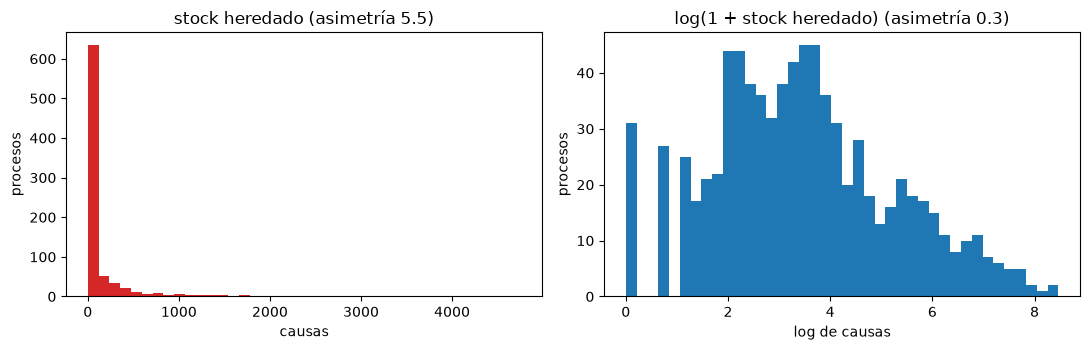

In [14]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.6))
ejes[0].hist(datos["pendientes_inicio_efectivo"], bins=40, color="tab:red")
ejes[0].set_title(f"stock heredado (asimetría {stats.skew(datos['pendientes_inicio_efectivo']):.1f})")
ejes[0].set_xlabel("causas")
ejes[1].hist(datos["log_stock_inicial"], bins=40, color="tab:blue")
ejes[1].set_title(f"log(1 + stock heredado) (asimetría {stats.skew(datos['log_stock_inicial']):.1f})")
ejes[1].set_xlabel("log de causas")
for ax in ejes:
    ax.set_ylabel("procesos")
plt.tight_layout()
guardar_figura(fig, "nb19_3.png")
plt.show()

## 1.4 Conversión
| paso | qué hace | por qué |
|---|---|---|
| objetivo | días → $\log(1 + \text{días})$, con tope de 10 años | los tiempos van de 0 a miles de días; en log, «el doble» pesa igual en un proceso rápido y en uno lento |
| tipos | `Int64` con `<NA>` → `float64`; texto → `object` | scikit-learn no acepta el entero con nulos de pandas |
| ingeniería | 8 variables nuevas calculadas fila por fila | relaciones (cocientes, logs) que un modelo lineal o el SVM no construyen solos |
| historia | 1 variable de la serie por materia (capítulo 9) | el ritmo de la materia el año anterior |
| one-hot | cada categoría → una columna 0/1 | el modelo necesita números; un código 1, 2, 3 inventaría un orden |
| escala | media 0 y desvío 1 (solo SVM, regresión lineal y stacking) | el SVM mide distancias: sin escala, la remuneración (millones) taparía todo lo demás |

Todos estos pasos (menos el del objetivo) viven **dentro de un `Pipeline`**: se ajustan con el entrenamiento y se
aplican igual a la prueba.

In [15]:
tabla_ing = pd.DataFrame({"variable": INGENIERIA + HISTORICAS, "nombre": [NOMBRES[c] for c in INGENIERIA + HISTORICAS],
                          "formula": [FORMULAS[c] for c in INGENIERIA + HISTORICAS]})
display(tabla_ing)
pre = preprocesador(COMPLETA, escalar=True).fit(datos[COMPLETA])
matriz = pre.transform(datos[COMPLETA])
n_onehot = sum(datos[c].nunique() for c in CATEGORICAS)
print(f"{len(COMPLETA)} variables -> {matriz.shape[1]} columnas numéricas tras el one-hot "
      f"({len(COMPLETA) - len(CATEGORICAS)} numéricas + {n_onehot} de {len(CATEGORICAS)} categóricas)")
assert matriz.shape[1] == len(COMPLETA) - len(CATEGORICAS) + n_onehot
assert np.isfinite(matriz).all()

,variable,nombre,formula
0,log_stock_inicial,log del stock heredado,log(1 + stock heredado)
1,log_ingresos,log de los ingresos,log(1 + ingresos del año)
2,presion_stock,presión del stock,stock heredado / (ingresos del año + 1)
3,ingresos_por_juzgado,ingresos por juzgado,ingresos del año / juzgados
4,stock_por_juzgado,stock por juzgado,stock heredado / juzgados
5,prop_acefalias,proporción de vacantes,puestos vacantes / puestos totales
6,prop_excusa,proporción por excusa,recibidas por excusa / (ingresos del año + 1)
7,sin_stock_inicial,sin stock heredado,1 si no había stock heredado
8,tendencia_resueltas_materia,tendencia histórica de la materia,resueltas del año anterior / resueltas de dos ...


28 variables -> 41 columnas numéricas tras el one-hot (25 numéricas + 16 de 3 categóricas)


## Partición entrenamiento / prueba
80 % para entrenar y ajustar (con validación cruzada de 5 pliegues), 20 % guardado para la evaluación final del
notebook 21. La partición es **estratificada por quintiles del tiempo**: las dos partes tienen la misma mezcla de
procesos rápidos y lentos.

In [16]:
idx_tr, idx_te = particion(datos)
part = pd.Series("entrenamiento", index=datos.index)
part[idx_te] = "prueba"
pd.DataFrame({"fila": datos.index, "particion": part, "tipo_proceso": datos["tipo_proceso"],
              "territorio": datos["territorio"], OBJETIVO: y}).to_csv(MODELO_DIR / "particion.csv", index=False)
print(len(idx_tr), "entrenamiento;", len(idx_te), "prueba")
print("mediana del tiempo (días):", round(datos.loc[idx_tr, DIAS].median()), "vs", round(datos.loc[idx_te, DIAS].median()))
assert abs(y[idx_tr].mean() - y[idx_te].mean()) < 0.15

646 entrenamiento; 162 prueba
mediana del tiempo (días): 224 vs 210


## Diccionario de variables del modelo

In [17]:
filas_var = []
for c in COMPLETA:
    filas_var.append({
        "variable": c, "nombre": NOMBRES[c],
        "grupo": "original" if c in ORIGINALES else ("histórica" if c in HISTORICAS else "ingeniería"),
        "tipo": "categórica" if c in CATEGORICAS else "numérica",
        "conversion": ("one-hot" if c in CATEGORICAS else
                       "cero estructural + imputación mediana + escala (SVM)" if c in CEROS_ESTRUCTURALES else
                       "imputación mediana + escala (SVM)"),
        "formula": FORMULAS.get(c, ""), "motivo_exclusion": "",
    })
for c, motivo in FUGA.items():
    filas_var.append({"variable": c, "nombre": c, "grupo": "excluida (fuga)", "tipo": "", "conversion": "",
                      "formula": "", "motivo_exclusion": motivo})
variables = pd.DataFrame(filas_var)
variables.to_csv(MODELO_DIR / "variables.csv", index=False)
variables["grupo"].value_counts()

grupo
original           19
excluida (fuga)    19
ingeniería          8
histórica           1
Name: count, dtype: int64

## Lectura
- **El objetivo práctico:** estimar cuánto tarda un caso, medido como el tiempo de la fila de su tipo de proceso y lugar
  (`pendientes al cierre ÷ resueltas × 365`). Es un número, así que el problema es de **regresión**.
- **La historia respalda la medida.** En 47 comprobaciones (capitales, provincias y país, 2007-2022), el tiempo estimado
  quedó a una mediana de **11,7 %** de lo que la fila de verdad tardó en vaciarse con las resoluciones de los años
  siguientes; tiende a pasarse un poco (+5,4 %), o sea que es algo pesimista. No es un plazo exacto, pero mide lo que dice medir.
- **El tiempo de un año anticipa bien el del siguiente:** usar el tiempo del año anterior se equivoca en una mediana de
  **8,8 %** (el peor caso, 35 %, en la pandemia). La fórmula ingenua (stock ÷ ingresos) se equivoca 25 % y siempre se
  queda corta (−24 %): supone que se resuelve todo lo que entra, y casi nunca pasa. Por eso el dato del último Anuario
  sirve para quien presenta su caso después, y por eso el modelo se compara contra la fórmula ingenua.
- **El país:** el tiempo nacional subió de 359 días (2007) a 448 (2012), bajó a 316 (2015), saltó a 485 en la pandemia
  (2020) y quedó en **340 días en 2023**, el más bajo desde 2015. Las capitales (331) ya son más rápidas que las provincias (365).
- **Las materias aceleran:** de 2020 a 2023 las resoluciones no penales crecieron en todas las materias (Trabajo en
  provincias +117 %, Civil en capitales +77 %). La variable histórica del modelo es el cambio del **año anterior** (para 2023,
  2022 contra 2021): va de −3 % (Niñez en capitales) a +41 % (Trabajo en provincias).
- **El conjunto:** de 1.240 procesos con movimiento, 422 tienen menos de 10 causas (su «tiempo» sería una anécdota) y 10
  no resolvieron ninguna: quedan **808 procesos**. Tiempo mediano **221 días** (la mitad entre 100 y 503); 13 pasan de 10 años
  y se recortan a 3.650 días.
- **EDA:** las materias difieren mucho (mediana: Coactivo Fiscal 887 días, Trabajo 375, Civil 243, Familia 195, Niñez 146);
  capital y provincia, poco (209 contra 236). La variable que más acompaña al tiempo es la **presión del stock**
  (stock heredado ÷ ingresos, Spearman +0,64): donde la fila heredada es grande en relación con lo que entra, se tarda
  más. Los ingresos van al revés (−0,21): los procesos con mucho movimiento resuelven rápido.
- **Limpieza y conversión:** 19 columnas fuera por fuga; un solo faltante real (tribunales del territorio, 4 filas); el
  objetivo se modela en log (la asimetría pasa de 3,0 en días a −1,1 en log: la cola larga de procesos lentísimos desaparece, aunque queda una cola corta de procesos casi sin fila). 19 originales + 8 de ingeniería + 1 histórica = **28
  variables** (41 columnas tras el one-hot). Partición: 646 para entrenar y 162 para la prueba, con la misma mezcla de
  procesos rápidos y lentos (mediana 224 y 210 días).